# NLP Text Dataset Exploratory Data Analysis


#session 1

# Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

# Load Dataset

In [ ]:
df = pd.read_csv("dataset/IMDB Dataset.csv")

df.head()

# Dataset Overview


In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)


# Data Cleaning

In [ ]:
import re

def clean_text(text):
    text = text.lower()

    text = re.sub(r'<.*?>', '', text)

    text = re.sub(r'[^a-zA-Z\s]', '', text)

    return text

df['clean_review'] = df['review'].apply(clean_text)

# Sentiment Distribution


sns.countplot(x='sentiment', data=df)

plt.title("Sentiment Distribution")

plt.show()

#Save Graphs


In [ ]:
plt.savefig("images/sentiment_distribution.png")

# Session 2 — Text Cleaning and Preprocessing

In [ ]:
import re
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

#Download NLTK Resources

In [ ]:
nltk.download('punkt')

nltk.download('stopwords')

nltk.download('wordnet')

## Lowercasing

In [19]:
df['review'] = df['review'].str.lower()

df['review'].head()

0    one of the other reviewers has mentioned that ...
1    a wonderful little production. <br /><br />the...
2    i thought this was a wonderful way to spend ti...
3    basically there's a family where a little boy ...
4    petter mattei's "love in the time of money" is...
Name: review, dtype: str

## Removing HTML Tags and Special Characters

In [ ]:
%pip install pandas

In [5]:
import re
import pandas as pd

# 1. Load the dataset fresh (stepping up out of 'notebook' folder into 'dataset')
df = pd.read_csv('../dataset/IMDB Dataset.csv')

# 2. Optimized, high-speed cleaning function
def clean_text_fast(text):
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Keep only letters; combine special chars and spaces into a single space instantly
    text = re.sub(r'[^a-zA-Z]+', ' ', text)
    return text.strip().lower()

# 3. Apply everything in a single, fast pass
df['clean_review'] = df['review'].apply(clean_text_fast)

# 4. View your results immediately
df['clean_review'].head()

0    one of the other reviewers has mentioned that ...
1    a wonderful little production the filming tech...
2    i thought this was a wonderful way to spend ti...
3    basically there s a family where a little boy ...
4    petter mattei s love in the time of money is a...
Name: clean_review, dtype: str

## Tokenization

In [8]:
%pip install nltk

  Using cached nltk-3.9.4-py3-none-any.whl.metadata (3.2 kB)
  Using cached click-8.4.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached tqdm-4.67.3-py3-none-any.whl.metadata (57 kB)
Using cached nltk-3.9.4-py3-none-any.whl (1.6 MB)
Using cached click-8.4.1-py3-none-any.whl (116 kB)
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
Using cached tqdm-4.67.3-py3-none-any.whl (78 kB)

   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   -------- ------------------------------- 1/5 [regex]
   -------- ------------------------------- 1/5 [regex]
   ---------------- ----------------------- 2/5 [joblib]
   ---------------- ----------------------- 2/5 [j


[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import nltk
from nltk.tokenize import word_tokenize

# Download the required punctuation datasets for tokenization
nltk.download("punkt")
nltk.download("punkt_tab")

# Apply tokenization to your cleaned reviews
df["tokens"] = df["clean_review"].apply(word_tokenize)

# View the output list of words
df["tokens"].head()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\A\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\A\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


0    [one, of, the, other, reviewers, has, mentione...
1    [a, wonderful, little, production, the, filmin...
2    [i, thought, this, was, a, wonderful, way, to,...
3    [basically, there, s, a, family, where, a, lit...
4    [petter, mattei, s, love, in, the, time, of, m...
Name: tokens, dtype: object

## Stopword Removal


In [10]:
import nltk
from nltk.corpus import stopwords

# Download the official NLTK stopwords dataset (only needs to run once)
nltk.download('stopwords')

# Load the set of English stop words
stop_words = set(stopwords.words('english'))

# Filter out the stop words from each list of tokens
df['tokens'] = df['tokens'].apply(
    lambda x: [word for word in x if word.lower() not in stop_words]
)

# View your cleaned tokens list
df['tokens'].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\A\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


0    [one, reviewers, mentioned, watching, oz, epis...
1    [wonderful, little, production, filming, techn...
2    [thought, wonderful, way, spend, time, hot, su...
3    [basically, family, little, boy, jake, thinks,...
4    [petter, mattei, love, time, money, visually, ...
Name: tokens, dtype: object

## Lemmatization

In [11]:
import nltk
from nltk.stem import WordNetLemmatizer

# Download the WordNet database and OMW (Open Multilingual Wordnet) datasets
nltk.download('wordnet')
nltk.download('omw-1.4')

# Initialize the lemmatizer
lemmatizer = WordNetLemmatizer()

# Apply lemmatization to each word in your tokens lists
df['tokens'] = df['tokens'].apply(
    lambda x: [lemmatizer.lemmatize(word) for word in x]
)

# View your beautifully lemmatized tokens list
df['tokens'].head()

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\A\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\A\AppData\Roaming\nltk_data...


0    [one, reviewer, mentioned, watching, oz, episo...
1    [wonderful, little, production, filming, techn...
2    [thought, wonderful, way, spend, time, hot, su...
3    [basically, family, little, boy, jake, think, ...
4    [petter, mattei, love, time, money, visually, ...
Name: tokens, dtype: object

## Word Frequency Analysis

In [12]:
from collections import Counter
import pandas as pd

# 1. Flatten the lists of tokens into a single list of all words
all_words = []
for tokens in df['tokens']:
    all_words.extend(tokens)

# 2. Count the word frequencies
word_freq = Counter(all_words)

# 3. Convert the top 20 most common words into a beautiful Pandas DataFrame
top_20_words = pd.DataFrame(word_freq.most_common(20), columns=['Word', 'Frequency'])

# 4. Display the table smoothly
top_20_words

,Word,Frequency
0,movie,103238
1,film,93428
2,one,55432
3,like,41120
4,time,31455
5,good,29852
6,character,28344
7,story,25263
8,even,24857
9,get,24650


#Visualization — Top Words

In [14]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 699.1 kB/s eta 0:00:12
   -- ------------------------------------- 0.5/8.2 MB 699.1 kB/s eta 0:00:12
   -- ------------------------------------- 0.5/8.2 MB 699.1 kB/s eta 0:00:12
   --- ------------------------------------ 0.8/8.2 MB 570.7 kB/s eta 0:00:14
   --- ------------------------------------ 0.8/8.2 MB 570.7 kB/s eta 0:00:14
   ----- ---------------------------------- 1.0/8.2 MB 542.4 kB/s eta 0:00:14
   ----- ---------------------------------- 1.0/8.2 MB 542.4 kB/s eta 0:00:14
   ----- ---------------------------------- 1.0/8.2 MB 542.4 kB/s eta 0:00:14
   ------ -----------------------------


[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


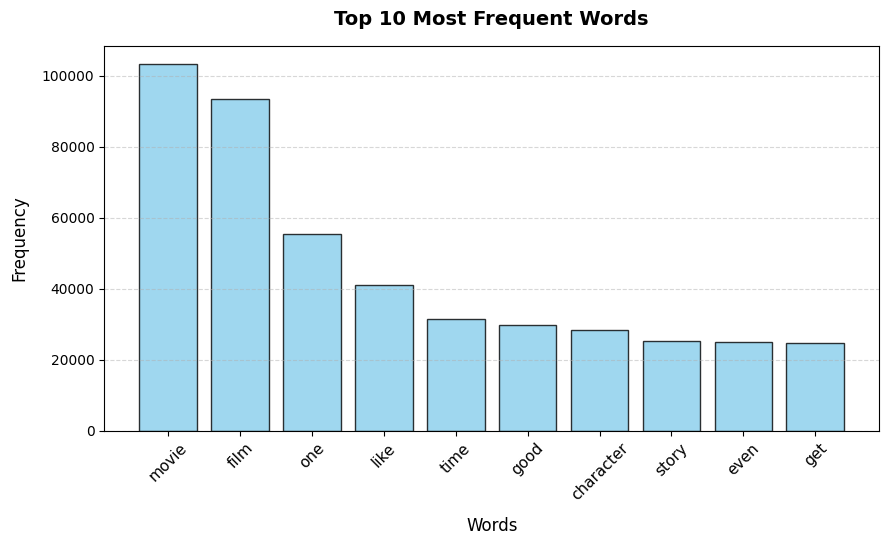

In [15]:
import matplotlib.pyplot as plt

# 1. Extract the top 10 most common words and their counts
common_words = word_freq.most_common(10)
words = [word[0] for word in common_words]
counts = [word[1] for word in common_words]

# 2. Initialize the plot canvas layout
plt.figure(figsize=(10, 5))

# 3. Build the bar chart with a clean color scheme
plt.bar(words, counts, color='skyblue', edgecolor='black', alpha=0.8)

# 4. Set up highly readable styling, titles, and labels
plt.title("Top 10 Most Frequent Words", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Words", fontsize=12, labelpad=10)
plt.ylabel("Frequency", fontsize=12, labelpad=10)
plt.xticks(rotation=45, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 5. Correct the path to step out of 'notebook' and into the 'images' folder
plt.savefig("../images/top_words.png", bbox_inches='tight')

# 6. Render it cleanly underneath the cell
plt.show()

## WordCloud Visualization


In [17]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


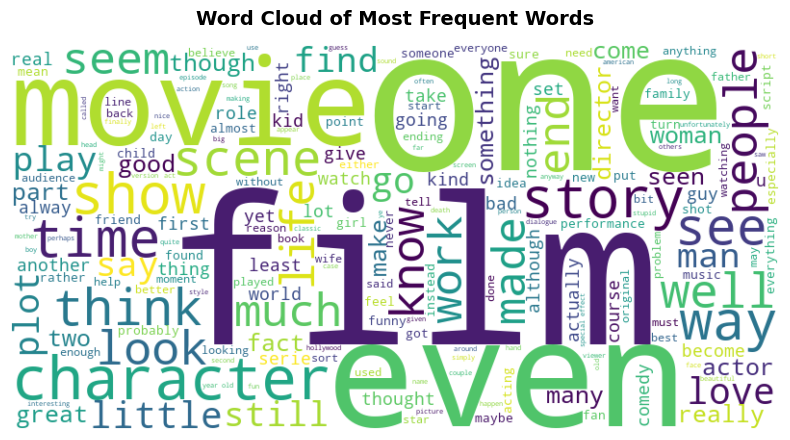

In [18]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 1. Join all single words in your list into one massive block of text
text = " ".join(all_words)

# 2. Build and configure the WordCloud object
wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color='white',
    colormap='viridis'
).generate(text)

# 3. Set up the display canvas
plt.figure(figsize=(10, 5))

# 4. Render the word cloud array as an image with smooth pixel scaling
plt.imshow(wordcloud, interpolation='bilinear')

# 5. Clean up the plot layout by hiding the graph axes and grid lines
plt.axis('off')

# 6. Add a title
plt.title("Word Cloud of Most Frequent Words", fontsize=14, fontweight='bold', pad=15)

# 7. Correct the path to step out of 'notebook' and into the 'images' folder
plt.savefig("../images/wordcloud.png", bbox_inches='tight')

# 8. Render it cleanly underneath the cell
plt.show()

# Session 3 — Advanced Text Analysis and Insights


## Review Length Analysis

In [5]:
import pandas as pd

df = pd.read_csv("../dataset/IMDB Dataset.csv")

df['review_length'] = df['review'].apply(len)

df['review_length'].describe()

count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: review_length, dtype: float64

#Histogram Visualization

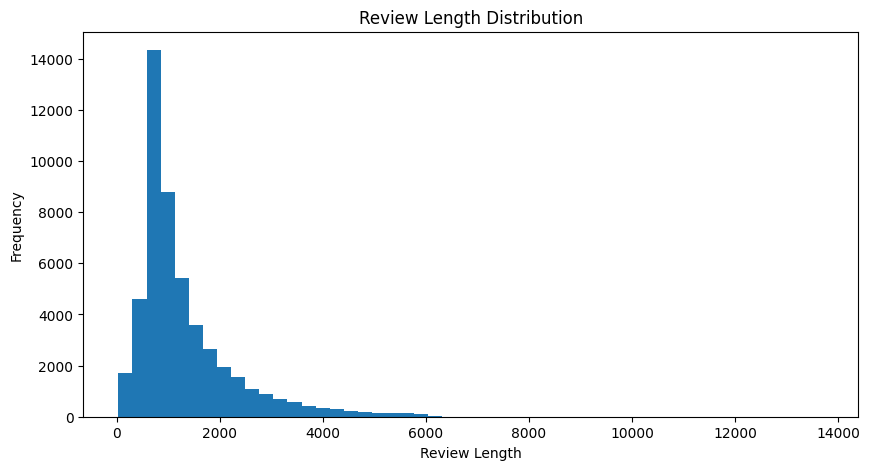

In [7]:
import matplotlib.pyplot as plt
import os


if not os.path.exists("images"):
    os.makedirs("images")


plt.figure(figsize=(10, 5))
plt.hist(df['review_length'], bins=50)


plt.title("Review Length Distribution")
plt.xlabel("Review Length")
plt.ylabel("Frequency")

plt.savefig("images/review_length_histogram.png")
plt.show()

## Bigram Analysis

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\A\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Top 10 Bigrams: [(('<', 'br'), 201948), (('br', '/'), 201948), (('/', '>'), 201948), (('>', '<'), 101016), (('of', 'the'), 75037), ((',', 'and'), 58500), (('.', 'The'), 50764), (('in', 'the'), 46170), ((',', 'but'), 41646), (('.', 'I'), 37437)]


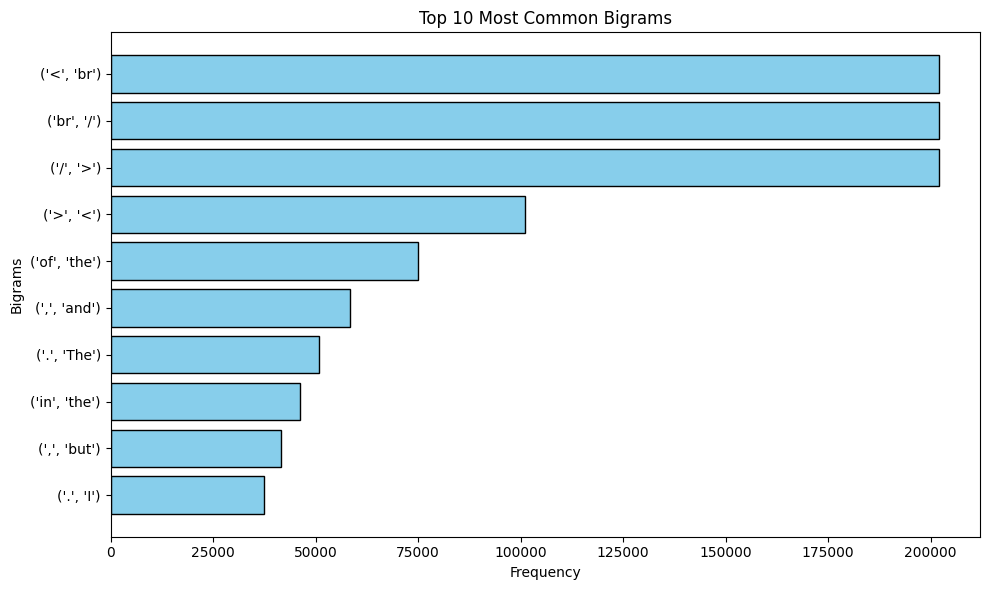

Success! The chart has been saved to 'images/top_10_bigrams.png'


In [10]:
from collections import Counter
import os
import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk.util import ngrams

# Download the required tokenizer resource if you haven't already
nltk.download('punkt')

# 1. Double-check your column name! 
# If your text column is named 'review', we will tokenize it into a new 'tokens' column.
if 'tokens' not in df.columns:
    # This automatically tokenizes sentences into lists of words, ignoring missing values
    df['tokens'] = df['review'].dropna().apply(nltk.word_tokenize)

# Drop any rows where tokens couldn't be generated
clean_tokens = df['tokens'].dropna()

# 2. Extract bigrams loop
bigrams = []
for tokens in clean_tokens:
    bigrams.extend(list(ngrams(tokens, 2)))

# 3. Count frequencies
bigram_freq = Counter(bigrams)
top_10_bigrams = bigram_freq.most_common(10)

# Print the text result to the console
print("Top 10 Bigrams:", top_10_bigrams)

# 4. Create the 'images' folder if it doesn't exist
if not os.path.exists("images"):
    os.makedirs("images")

# 5. Convert the top 10 bigrams into a nice horizontal bar chart and save it
if top_10_bigrams:
    # Format the bigram tuples into strings like "('word1', 'word2')" for the chart labels
    labels = [str(bg[0]) for bg in top_10_bigrams]
    counts = [bg[1] for bg in top_10_bigrams]
    
    # Reverse them so the highest frequency is at the top of the chart
    labels.reverse()
    counts.reverse()

    plt.figure(figsize=(10, 6))
    plt.barh(labels, counts, color='skyblue', edgecolor='black')
    plt.xlabel('Frequency')
    plt.ylabel('Bigrams')
    plt.title('Top 10 Most Common Bigrams')
    plt.tight_layout()
    
    # Save the chart as an image file
    plt.savefig("images/top_10_bigrams.png")
    plt.show()
    print("Success! The chart has been saved to 'images/top_10_bigrams.png'")
else:
    print("No bigrams found. Make sure your dataset columns contain valid text data.")